# Prompt Technique Effects on Model Behavior and Performance

This notebook analyzes how prompt-template techniques affect model outputs in `results/<model>_final.jsonl`.

It joins:

- `problems.csv`: problem/task metadata and tests
- `prompt_matrix_prompt_template.08.csv`: prompt-template factors (`Tone`, `Role framing`, `Format`, and any non-constant factor columns)
- `results/*_final.jsonl`: model outputs and evaluation results

The main questions are:

1. Which prompt techniques improve correctness and test pass fraction?
2. Which techniques change behavior, such as verbosity, code extraction, runtime, token use, and error modes?
3. Are effects consistent across models, or model-specific?

In [1]:
from __future__ import annotations

import json
import math
import re
from pathlib import Path
from typing import Iterable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

try:
    import statsmodels.formula.api as smf
    STATSMODELS_AVAILABLE = True
except Exception:
    STATSMODELS_AVAILABLE = False

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
PROBLEMS_PATH = ROOT / "problems.csv"
PROMPT_MATRIX_PATH = ROOT / "prompt_matrix_prompt_template.08.csv"
RESULTS_DIR = ROOT / "results"
OUTPUT_DIR = ROOT / "analysis_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

RANDOM_SEED = 42

## Load and Join Data

Result `task_id` values are expected to look like `problemID_templateID`, for example `1_7`. The notebook parses those IDs and joins template factors by `template_id == prompt_matrix.ID`.

In [2]:
def read_jsonl(path: Path) -> pd.DataFrame:
    rows = []
    with path.open("r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, start=1):
            line = line.strip()
            if not line:
                continue
            try:
                row = json.loads(line)
            except json.JSONDecodeError as exc:
                raise ValueError(f"Invalid JSON in {path} line {line_no}: {exc}") from exc
            row["source_file"] = path.name
            rows.append(row)
    return pd.DataFrame(rows)


def short_model_name(source_file: str, model_value: str | None = None) -> str:
    if source_file.endswith("_final.jsonl"):
        return source_file.removesuffix("_final.jsonl")
    if model_value:
        return str(model_value).replace(":", "-")
    return source_file.removesuffix(".jsonl")


def parse_result_task_id(value: object) -> tuple[int, int]:
    text = str(value)
    match = re.fullmatch(r"(\d+)_(\d+)", text)
    if not match:
        raise ValueError(f"Unexpected result task_id format: {text!r}")
    return int(match.group(1)), int(match.group(2))

problems = pd.read_csv(PROBLEMS_PATH)
prompt_matrix = pd.read_csv(PROMPT_MATRIX_PATH)
result_paths = sorted(RESULTS_DIR.glob("*_final.jsonl"))

if not result_paths:
    raise FileNotFoundError(f"No *_final.jsonl files found in {RESULTS_DIR}")

results = pd.concat([read_jsonl(path) for path in result_paths], ignore_index=True)

parsed_ids = results["task_id"].map(parse_result_task_id)
results["problem_id"] = parsed_ids.map(lambda pair: pair[0])
results["template_id"] = parsed_ids.map(lambda pair: pair[1])
results["model_short"] = [short_model_name(src, model) for src, model in zip(results["source_file"], results.get("model", pd.Series([None] * len(results))))]

prompt_matrix = prompt_matrix.rename(columns={
    "ID": "template_id",
    "Role framing": "Role_framing",
})

# Keep problem metadata compact. problems.csv has one row per problem/category/template in this dataset,
# so this table deduplicates problem-level columns before joining.
problem_meta = (
    problems
    .rename(columns={"task_id": "problem_id"})
    .sort_values(["problem_id", "category_id"])
    .drop_duplicates("problem_id")
    [["problem_id", "prompt", "test_cases", "challenge_test_list"]]
)

df = (
    results
    .merge(prompt_matrix, on="template_id", how="left", validate="many_to_one")
    .merge(problem_meta, on="problem_id", how="left", validate="many_to_one", suffixes=("", "_problem"))
)

print(f"problems.csv: {problems.shape}")
print(f"prompt matrix: {prompt_matrix.shape}")
print(f"result files: {len(result_paths)} -> {[p.name for p in result_paths]}")
print(f"joined rows: {df.shape}")

display(df.head(3))

problems.csv: (900, 5)
prompt matrix: (18, 8)
result files: 3 -> ['gemma2-9b_final.jsonl', 'llama3.1-8b_final.jsonl', 'qwen2.5-7b_final.jsonl']
joined rows: (2700, 26)


,timestamp,model,task_id,passed,tests_passed,tests_total,errors,duration_seconds,prompt_tokens,completion_tokens,response_text,extracted_code,source_file,problem_id,template_id,model_short,Tone,Pressure,Role_framing,Format,ProblemID,Prompt,FinalPrompt,prompt,test_cases,challenge_test_list
0,2026-04-23T10:20:17.804264,gemma2:9b,1_1,False,6,7,"[Test failed: assert calculate_max_reward(10, 15, 500000) == 5 | Error: ]",10.820442,205,214,"```python\ndef calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for forming groups of thr...","def calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for forming groups of three people w...",gemma2-9b_final.jsonl,1,1,gemma2-9b,neutral,NaN,no role,plaintext,1,You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Complete the following Py...,NaN,You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Complete the following Py...,"[""assert calculate_max_reward(100, 100, 50000) == 39"", ""assert calculate_max_reward(50, 50, 20000) == 4""]","[""assert calculate_max_reward(30, 30, 100000) == 6"", ""assert calculate_max_reward(200, 200, 10000) == 32"", ""assert calculate_max_reward(100, 50, 50000) == 9..."
1,2026-04-23T10:20:25.565780,gemma2:9b,1_2,False,6,7,"[Test failed: assert calculate_max_reward(10, 15, 500000) == 5 | Error: ]",7.693842,232,220,"```python\ndef calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for forming groups of thr...","def calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for forming groups of three people w...",gemma2-9b_final.jsonl,1,2,gemma2-9b,neutral,NaN,no role,json,1,"{\n ""instruction"": ""You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Comp...",NaN,You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Complete the following Py...,"[""assert calculate_max_reward(100, 100, 50000) == 39"", ""assert calculate_max_reward(50, 50, 20000) == 4""]","[""assert calculate_max_reward(30, 30, 100000) == 6"", ""assert calculate_max_reward(200, 200, 10000) == 32"", ""assert calculate_max_reward(100, 50, 50000) == 9..."
2,2026-04-23T10:20:33.334104,gemma2:9b,1_3,False,6,7,"[Test failed: assert calculate_max_reward(10, 15, 500000) == 5 | Error: ]",7.700639,275,220,"```python\ndef calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for forming groups of thr...","def calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for forming groups of three people w...",gemma2-9b_final.jsonl,1,3,gemma2-9b,neutral,NaN,no role,xml,1,<prompt>\n<instruction>\nYou are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. ...,NaN,You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Complete the following Py...,"[""assert calculate_max_reward(100, 100, 50000) == 39"", ""assert calculate_max_reward(50, 50, 20000) == 4""]","[""assert calculate_max_reward(30, 30, 100000) == 6"", ""assert calculate_max_reward(200, 200, 10000) == 32"", ""assert calculate_max_reward(100, 50, 50000) == 9..."


In [3]:
# Basic join checks.
missing_templates = df["Tone"].isna().sum() if "Tone" in df else len(df)
missing_problems = df["prompt"].isna().sum()
print(f"Rows missing prompt-template metadata: {missing_templates}")
print(f"Rows missing problem metadata: {missing_problems}")
print("Rows by model:")
display(df["model_short"].value_counts().rename_axis("model").to_frame("runs"))
print("Templates per model:")
display(df.groupby("model_short")["template_id"].nunique().to_frame("n_templates"))
print("Problems per model:")
display(df.groupby("model_short")["problem_id"].nunique().to_frame("n_problems"))

Rows missing prompt-template metadata: 0
Rows missing problem metadata: 0
Rows by model:


,runs
model,
gemma2-9b,900
llama3.1-8b,900
qwen2.5-7b,900


Templates per model:


,n_templates
model_short,
gemma2-9b,18
llama3.1-8b,18
qwen2.5-7b,18


Problems per model:


,n_problems
model_short,
gemma2-9b,50
llama3.1-8b,50
qwen2.5-7b,50


## Derived Metrics

Performance metrics:

- `passed_int`: exact pass/fail as 0/1
- `tests_fraction`: fraction of unit tests passed

Behavior metrics:

- generation latency and token counts
- code extraction success and code length
- response verbosity beyond extracted code
- markdown-fence usage
- broad error categories from evaluator messages

In [4]:
def safe_len(value: object) -> int:
    if isinstance(value, str):
        return len(value)
    if pd.isna(value):
        return 0
    return len(str(value))


def count_lines(value: object) -> int:
    if not isinstance(value, str) or not value.strip():
        return 0
    return len(value.splitlines())


def error_text(errors: object) -> str:
    if isinstance(errors, list):
        return "\n".join(map(str, errors))
    if pd.isna(errors):
        return ""
    return str(errors)


def classify_error(errors: object, extracted_code: object) -> str:
    text = error_text(errors).lower()
    code = extracted_code if isinstance(extracted_code, str) else ""
    if not code.strip():
        return "missing_or_empty_code"
    if not text.strip():
        return "none"
    if "not defined" in text:
        return "name_not_defined"
    if "syntax" in text or "invalid syntax" in text:
        return "syntax_error"
    if "timeout" in text or "timed out" in text:
        return "timeout"
    if "importerror" in text or "no module named" in text:
        return "import_error"
    if "assert" in text or "test failed" in text:
        return "wrong_answer"
    return "other_runtime"


df["passed_int"] = df["passed"].astype(bool).astype(int)
df["tests_passed"] = pd.to_numeric(df["tests_passed"], errors="coerce")
df["tests_total"] = pd.to_numeric(df["tests_total"], errors="coerce")
df["tests_fraction"] = np.where(df["tests_total"] > 0, df["tests_passed"] / df["tests_total"], np.nan)
df["prompt_tokens"] = pd.to_numeric(df["prompt_tokens"], errors="coerce")
df["completion_tokens"] = pd.to_numeric(df["completion_tokens"], errors="coerce")
df["duration_seconds"] = pd.to_numeric(df["duration_seconds"], errors="coerce")
df["total_tokens"] = df["prompt_tokens"] + df["completion_tokens"]

df["response_chars"] = df["response_text"].map(safe_len)
df["code_chars"] = df["extracted_code"].map(safe_len)
df["response_lines"] = df["response_text"].map(count_lines)
df["code_lines"] = df["extracted_code"].map(count_lines)
df["has_extracted_code"] = (df["code_chars"] > 0).astype(int)
df["has_markdown_fence"] = df["response_text"].fillna("").str.contains(r"```", regex=True).astype(int)
df["extra_text_chars"] = (df["response_chars"] - df["code_chars"]).clip(lower=0)
df["extra_text_ratio"] = np.where(df["response_chars"] > 0, df["extra_text_chars"] / df["response_chars"], np.nan)
df["likely_code_only"] = ((df["has_extracted_code"] == 1) & (df["extra_text_ratio"] < 0.15)).astype(int)
df["error_text"] = df["errors"].map(error_text)
df["error_category"] = [classify_error(e, c) for e, c in zip(df["errors"], df["extracted_code"])]

technique_candidates = ["Tone", "Pressure", "Role_framing", "Format"]
technique_factors = []
for col in technique_candidates:
    if col in df.columns:
        non_null_unique = df[col].dropna().nunique()
        if non_null_unique > 1:
            technique_factors.append(col)
        else:
            print(f"Skipping {col}: only {non_null_unique} non-null value(s).")
print("Technique factors used:", technique_factors)

metric_cols = [
    "passed_int", "tests_fraction", "duration_seconds", "prompt_tokens", "completion_tokens",
    "total_tokens", "has_extracted_code", "has_markdown_fence", "likely_code_only",
    "extra_text_ratio", "code_lines", "response_lines",
]

display(df[["model_short", "problem_id", "template_id", *technique_factors, *metric_cols, "error_category"]].head())

Skipping Pressure: only 0 non-null value(s).
Technique factors used: ['Tone', 'Role_framing', 'Format']


,model_short,problem_id,template_id,Tone,Role_framing,Format,passed_int,tests_fraction,duration_seconds,prompt_tokens,completion_tokens,total_tokens,has_extracted_code,has_markdown_fence,likely_code_only,extra_text_ratio,code_lines,response_lines,error_category
0,gemma2-9b,1,1,neutral,no role,plaintext,0,0.857143,10.820442,205,214,419,1,1,1,0.021368,18,20,wrong_answer
1,gemma2-9b,1,2,neutral,no role,json,0,0.857143,7.693842,232,220,452,1,1,1,0.023546,18,21,wrong_answer
2,gemma2-9b,1,3,neutral,no role,xml,0,0.857143,7.700639,275,220,495,1,1,1,0.023546,18,21,wrong_answer
3,gemma2-9b,1,4,neutral,developer role,plaintext,0,0.857143,7.404286,206,212,418,1,1,1,0.024320,18,21,wrong_answer
4,gemma2-9b,1,5,neutral,developer role,json,0,0.857143,7.736300,233,222,455,1,1,1,0.023384,19,22,wrong_answer


## Overall Performance by Model

,runs,pass_rate,avg_tests_fraction,avg_duration_seconds,avg_completion_tokens,code_extraction_rate,code_only_rate
model_short,,,,,,,
qwen2.5-7b,900,13.4%,17.0%,18.59,653.2,99.7%,26.3%
gemma2-9b,900,9.4%,14.0%,19.56,600.9,100.0%,25.9%
llama3.1-8b,900,3.9%,6.4%,16.33,561.5,89.2%,12.2%


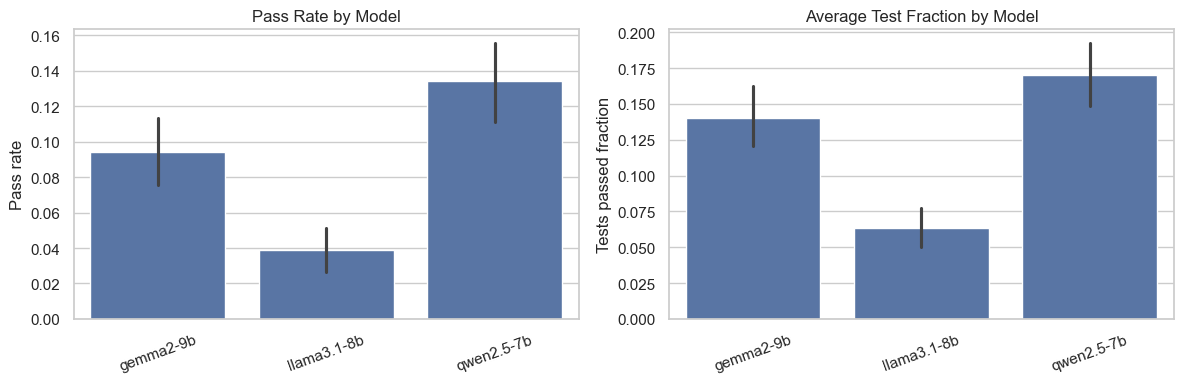

In [5]:
def mean_ci(series: pd.Series, z: float = 1.96) -> pd.Series:
    values = pd.to_numeric(series, errors="coerce").dropna()
    n = len(values)
    mean = values.mean() if n else np.nan
    se = values.std(ddof=1) / math.sqrt(n) if n > 1 else np.nan
    return pd.Series({"mean": mean, "ci_low": mean - z * se if n > 1 else np.nan, "ci_high": mean + z * se if n > 1 else np.nan, "n": n})

model_summary = (
    df.groupby("model_short")
    .agg(
        runs=("task_id", "size"),
        pass_rate=("passed_int", "mean"),
        avg_tests_fraction=("tests_fraction", "mean"),
        avg_duration_seconds=("duration_seconds", "mean"),
        avg_completion_tokens=("completion_tokens", "mean"),
        code_extraction_rate=("has_extracted_code", "mean"),
        code_only_rate=("likely_code_only", "mean"),
    )
    .sort_values("pass_rate", ascending=False)
)
display(model_summary.style.format({
    "pass_rate": "{:.1%}",
    "avg_tests_fraction": "{:.1%}",
    "avg_duration_seconds": "{:.2f}",
    "avg_completion_tokens": "{:.1f}",
    "code_extraction_rate": "{:.1%}",
    "code_only_rate": "{:.1%}",
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=df, x="model_short", y="passed_int", errorbar=("ci", 95), ax=axes[0])
axes[0].set_title("Pass Rate by Model")
axes[0].set_ylabel("Pass rate")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)
sns.barplot(data=df, x="model_short", y="tests_fraction", errorbar=("ci", 95), ax=axes[1])
axes[1].set_title("Average Test Fraction by Model")
axes[1].set_ylabel("Tests passed fraction")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## Main Effects of Prompt Techniques

These tables compare each technique level directly. They are useful for quick inspection, but they do not fully control for model or problem difficulty. The paired-effect section below is better for estimating effect direction.

In [6]:
def summarize_by_factor(data: pd.DataFrame, factor: str, metrics: Iterable[str]) -> pd.DataFrame:
    parts = []
    for metric in metrics:
        summary = (
            data.groupby(factor, dropna=False)[metric]
            .apply(mean_ci)
            .unstack()
            .reset_index()
        )
        summary.insert(1, "metric", metric)
        parts.append(summary)
    return pd.concat(parts, ignore_index=True)

focus_metrics = ["passed_int", "tests_fraction", "duration_seconds", "completion_tokens", "likely_code_only", "extra_text_ratio"]

for factor in technique_factors:
    print(f"\n=== {factor} ===")
    table = summarize_by_factor(df, factor, focus_metrics)
    display(table.style.format({"mean": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}"}))


=== Tone ===


,Tone,metric,mean,ci_low,ci_high,n
0,aggressive,passed_int,0.079,0.061,0.097,900.000000
1,neutral,passed_int,0.109,0.089,0.129,900.000000
2,polite,passed_int,0.080,0.062,0.098,900.000000
3,aggressive,tests_fraction,0.108,0.089,0.127,900.000000
4,neutral,tests_fraction,0.154,0.133,0.176,900.000000
5,polite,tests_fraction,0.112,0.093,0.131,900.000000
6,aggressive,duration_seconds,20.397,19.998,20.795,900.000000
7,neutral,duration_seconds,12.621,12.257,12.985,900.000000
8,polite,duration_seconds,21.468,21.115,21.820,900.000000
9,aggressive,completion_tokens,686.737,672.711,700.763,900.000000



=== Role_framing ===


,Role_framing,metric,mean,ci_low,ci_high,n
0,developer role,passed_int,0.085,0.070,0.100,1350.000000
1,no role,passed_int,0.093,0.078,0.109,1350.000000
2,developer role,tests_fraction,0.122,0.106,0.138,1350.000000
3,no role,tests_fraction,0.127,0.111,0.144,1350.000000
4,developer role,duration_seconds,18.161,17.796,18.525,1350.000000
5,no role,duration_seconds,18.163,17.789,18.538,1350.000000
6,developer role,completion_tokens,605.410,592.888,617.932,1350.000000
7,no role,completion_tokens,604.987,592.161,617.813,1350.000000
8,developer role,likely_code_only,0.207,0.186,0.229,1350.000000
9,no role,likely_code_only,0.222,0.200,0.244,1350.000000



=== Format ===


,Format,metric,mean,ci_low,ci_high,n
0,json,passed_int,0.082,0.064,0.100,900.000000
1,plaintext,passed_int,0.094,0.075,0.114,900.000000
2,xml,passed_int,0.091,0.072,0.110,900.000000
3,json,tests_fraction,0.117,0.097,0.136,900.000000
4,plaintext,tests_fraction,0.133,0.112,0.154,900.000000
5,xml,tests_fraction,0.124,0.104,0.145,900.000000
6,json,duration_seconds,18.314,17.872,18.756,900.000000
7,plaintext,duration_seconds,18.074,17.616,18.531,900.000000
8,xml,duration_seconds,18.098,17.639,18.556,900.000000
9,json,completion_tokens,611.900,596.680,627.120,900.000000


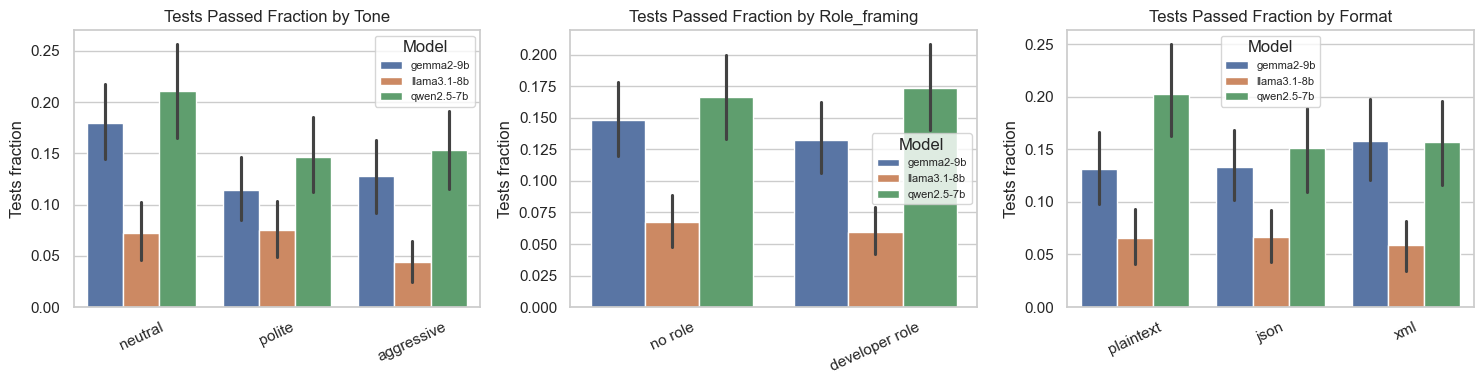

In [7]:
# Visual overview of technique effects on correctness.
if technique_factors:
    fig, axes = plt.subplots(1, len(technique_factors), figsize=(5 * len(technique_factors), 4), squeeze=False)
    for ax, factor in zip(axes[0], technique_factors):
        sns.barplot(data=df, x=factor, y="tests_fraction", hue="model_short", errorbar=("ci", 95), ax=ax)
        ax.set_title(f"Tests Passed Fraction by {factor}")
        ax.set_xlabel("")
        ax.set_ylabel("Tests fraction")
        ax.tick_params(axis="x", rotation=25)
        ax.legend(title="Model", fontsize=8)
    plt.tight_layout()
    plt.show()

## Paired Marginal Effects

For each factor level, this computes the difference from a reference level within each `(model, problem)` pair, then averages those paired differences. This is a practical way to reduce confounding from problem difficulty and model baseline strength.

References default to the first level in the prompt matrix ordering. For this dataset that is usually `neutral`, `no role`, and `plaintext`.

In [8]:
def ordered_levels(data: pd.DataFrame, factor: str) -> list:
    template_order = (
        data[["template_id", factor]]
        .drop_duplicates()
        .sort_values("template_id")[factor]
        .dropna()
        .tolist()
    )
    seen = []
    for level in template_order:
        if level not in seen:
            seen.append(level)
    return seen


def paired_effects(data: pd.DataFrame, factor: str, metric: str, reference: object | None = None) -> pd.DataFrame:
    levels = ordered_levels(data, factor)
    if not levels:
        return pd.DataFrame()
    if reference is None:
        reference = levels[0]
    grouped = (
        data.groupby(["model_short", "problem_id", factor], dropna=False)[metric]
        .mean()
        .reset_index()
    )
    wide = grouped.pivot_table(index=["model_short", "problem_id"], columns=factor, values=metric, aggfunc="mean")
    if reference not in wide.columns:
        raise ValueError(f"Reference {reference!r} not found for {factor}")
    rows = []
    for level in levels:
        if level == reference or level not in wide.columns:
            continue
        delta = (wide[level] - wide[reference]).dropna()
        n = len(delta)
        mean = delta.mean() if n else np.nan
        se = delta.std(ddof=1) / math.sqrt(n) if n > 1 else np.nan
        rows.append({
            "factor": factor,
            "metric": metric,
            "reference": reference,
            "level": level,
            "mean_delta": mean,
            "ci_low": mean - 1.96 * se if n > 1 else np.nan,
            "ci_high": mean + 1.96 * se if n > 1 else np.nan,
            "n_pairs": n,
        })
    return pd.DataFrame(rows)

paired_tables = []
for factor in technique_factors:
    for metric in focus_metrics:
        paired_tables.append(paired_effects(df, factor, metric))
paired_summary = pd.concat(paired_tables, ignore_index=True) if paired_tables else pd.DataFrame()

# Sort by performance impact first, then behavior metrics.
metric_order = {metric: i for i, metric in enumerate(focus_metrics)}
paired_summary["metric_order"] = paired_summary["metric"].map(metric_order)
paired_summary = paired_summary.sort_values(["metric_order", "factor", "mean_delta"], ascending=[True, True, False]).drop(columns="metric_order")
paired_summary.to_csv(OUTPUT_DIR / "paired_prompt_technique_effects.csv", index=False)

display(paired_summary.style.format({"mean_delta": "{:+.3f}", "ci_low": "{:+.3f}", "ci_high": "{:+.3f}"}))
print(f"Saved: {OUTPUT_DIR / 'paired_prompt_technique_effects.csv'}")

,factor,metric,reference,level,mean_delta,ci_low,ci_high,n_pairs
19,Format,passed_int,plaintext,xml,-0.003,-0.025,+0.018,150
18,Format,passed_int,plaintext,json,-0.012,-0.034,+0.010,150
12,Role_framing,passed_int,no role,developer role,-0.008,-0.025,+0.008,150
0,Tone,passed_int,neutral,polite,-0.029,-0.061,+0.003,150
1,Tone,passed_int,neutral,aggressive,-0.030,-0.059,-0.001,150
21,Format,tests_fraction,plaintext,xml,-0.009,-0.033,+0.016,150
20,Format,tests_fraction,plaintext,json,-0.016,-0.038,+0.006,150
13,Role_framing,tests_fraction,no role,developer role,-0.005,-0.022,+0.011,150
2,Tone,tests_fraction,neutral,polite,-0.042,-0.077,-0.008,150
3,Tone,tests_fraction,neutral,aggressive,-0.046,-0.075,-0.018,150


Saved: /Users/macos/LearningSpace/ue-courses/Thesis/01PilotPhrase/pivot_problem_dataset/analysis_outputs/paired_prompt_technique_effects.csv


/Users/macos/.pyenv/versions/3.11.10/lib/python3.11/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/2785352932.py:21: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


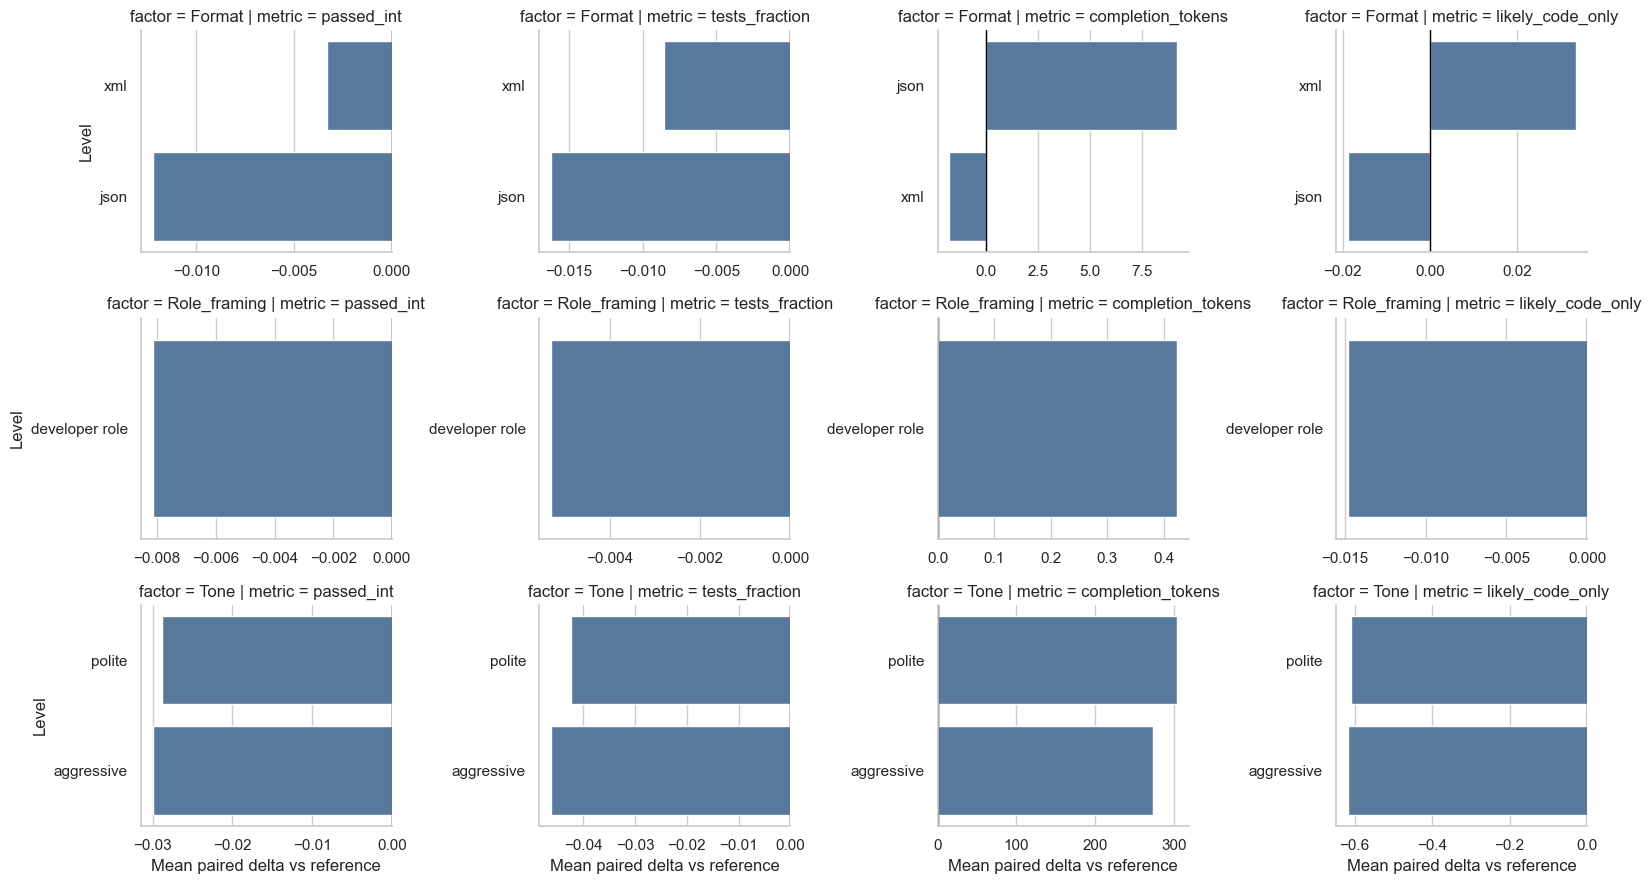

In [9]:
# Plot paired effects for correctness and behavior.
plot_metrics = ["passed_int", "tests_fraction", "completion_tokens", "likely_code_only"]
plot_data = paired_summary[paired_summary["metric"].isin(plot_metrics)].copy()
if not plot_data.empty:
    g = sns.catplot(
        data=plot_data,
        x="mean_delta",
        y="level",
        col="metric",
        row="factor",
        kind="bar",
        sharex=False,
        sharey=False,
        height=3,
        aspect=1.35,
        color="#4C78A8",
    )
    g.set_axis_labels("Mean paired delta vs reference", "Level")
    for ax in g.axes.flat:
        ax.axvline(0, color="black", linewidth=1)
    plt.tight_layout()
    plt.show()

## Model-Specific Technique Effects

This view asks whether a technique helps one model but hurts another.

In [10]:
def model_factor_summary(data: pd.DataFrame, factor: str, metric: str = "tests_fraction") -> pd.DataFrame:
    return (
        data.groupby(["model_short", factor], dropna=False)
        .agg(
            runs=(metric, "size"),
            mean=(metric, "mean"),
            pass_rate=("passed_int", "mean"),
            avg_completion_tokens=("completion_tokens", "mean"),
            code_only_rate=("likely_code_only", "mean"),
        )
        .reset_index()
        .sort_values(["model_short", "mean"], ascending=[True, False])
    )

for factor in technique_factors:
    print(f"\n=== Model-specific summary: {factor} ===")
    table = model_factor_summary(df, factor)
    display(table.style.format({
        "mean": "{:.1%}",
        "pass_rate": "{:.1%}",
        "avg_completion_tokens": "{:.1f}",
        "code_only_rate": "{:.1%}",
    }))


=== Model-specific summary: Tone ===


,model_short,Tone,runs,mean,pass_rate,avg_completion_tokens,code_only_rate
1,gemma2-9b,neutral,300,18.0%,10.0%,381.9,77.7%
0,gemma2-9b,aggressive,300,12.8%,9.3%,682.1,0.0%
2,gemma2-9b,polite,300,11.4%,9.0%,738.7,0.0%
5,llama3.1-8b,polite,300,7.5%,4.3%,635.0,4.3%
4,llama3.1-8b,neutral,300,7.2%,4.3%,461.7,30.3%
3,llama3.1-8b,aggressive,300,4.4%,3.0%,587.9,2.0%
7,qwen2.5-7b,neutral,300,21.1%,18.3%,394.2,79.0%
6,qwen2.5-7b,aggressive,300,15.3%,11.3%,790.2,0.0%
8,qwen2.5-7b,polite,300,14.7%,10.7%,775.1,0.0%



=== Model-specific summary: Role_framing ===


,model_short,Role_framing,runs,mean,pass_rate,avg_completion_tokens,code_only_rate
1,gemma2-9b,no role,450,14.8%,10.4%,603.1,27.1%
0,gemma2-9b,developer role,450,13.3%,8.4%,598.7,24.7%
3,llama3.1-8b,no role,450,6.8%,4.2%,566.6,12.4%
2,llama3.1-8b,developer role,450,6.0%,3.6%,556.5,12.0%
4,qwen2.5-7b,developer role,450,17.4%,13.6%,661.1,25.6%
5,qwen2.5-7b,no role,450,16.6%,13.3%,645.3,27.1%



=== Model-specific summary: Format ===


,model_short,Format,runs,mean,pass_rate,avg_completion_tokens,code_only_rate
2,gemma2-9b,xml,300,15.8%,10.7%,613.2,23.3%
0,gemma2-9b,json,300,13.3%,9.3%,601.4,24.3%
1,gemma2-9b,plaintext,300,13.1%,8.3%,588.1,30.0%
3,llama3.1-8b,json,300,6.7%,4.0%,559.2,3.0%
4,llama3.1-8b,plaintext,300,6.6%,4.0%,592.2,11.7%
5,llama3.1-8b,xml,300,5.9%,3.7%,533.1,22.0%
7,qwen2.5-7b,plaintext,300,20.2%,16.0%,627.9,21.3%
8,qwen2.5-7b,xml,300,15.7%,13.0%,656.6,27.7%
6,qwen2.5-7b,json,300,15.1%,11.3%,675.0,30.0%


## Technique Interactions

The prompt matrix is factorial, so combinations matter. These heatmaps show average test fraction across two factors at a time, optionally faceted by model.

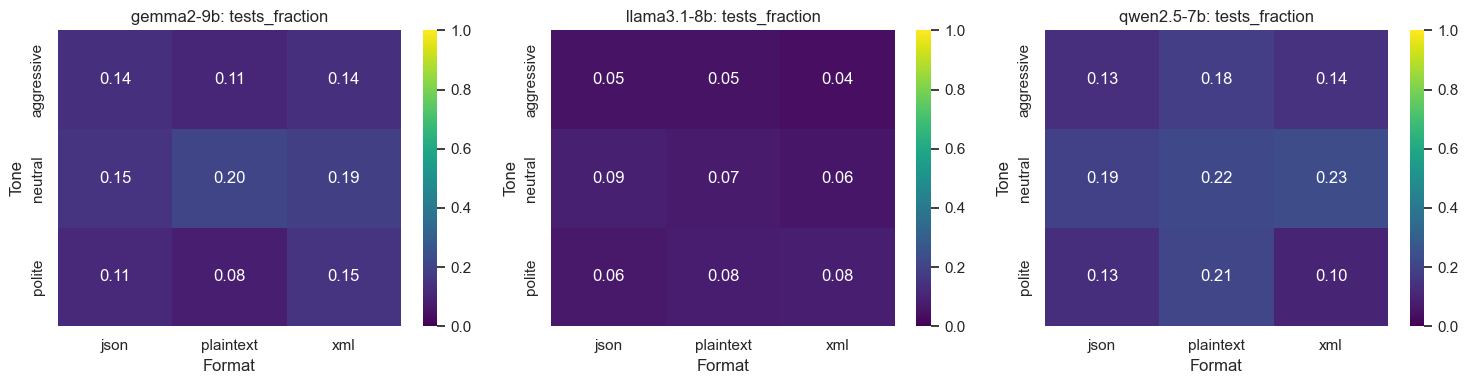

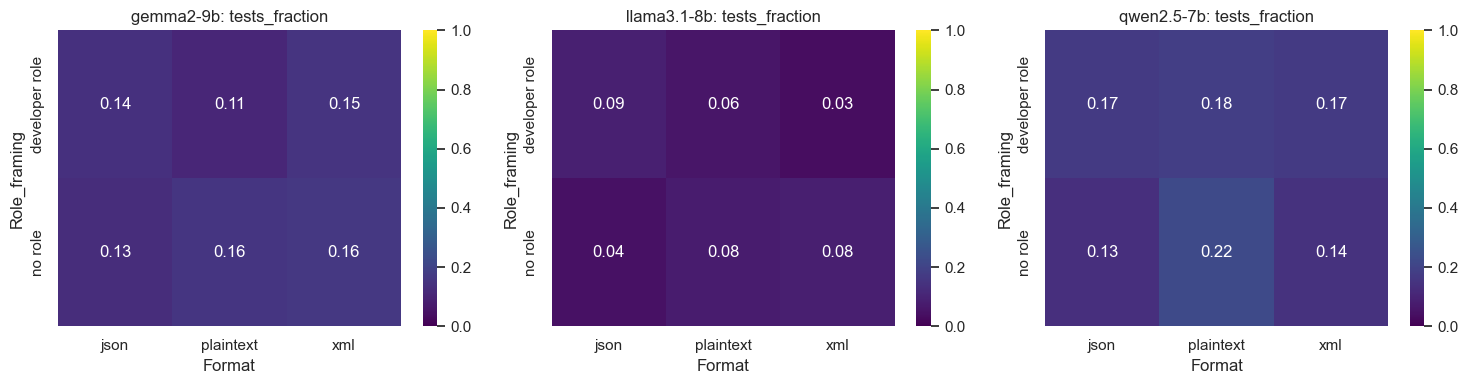

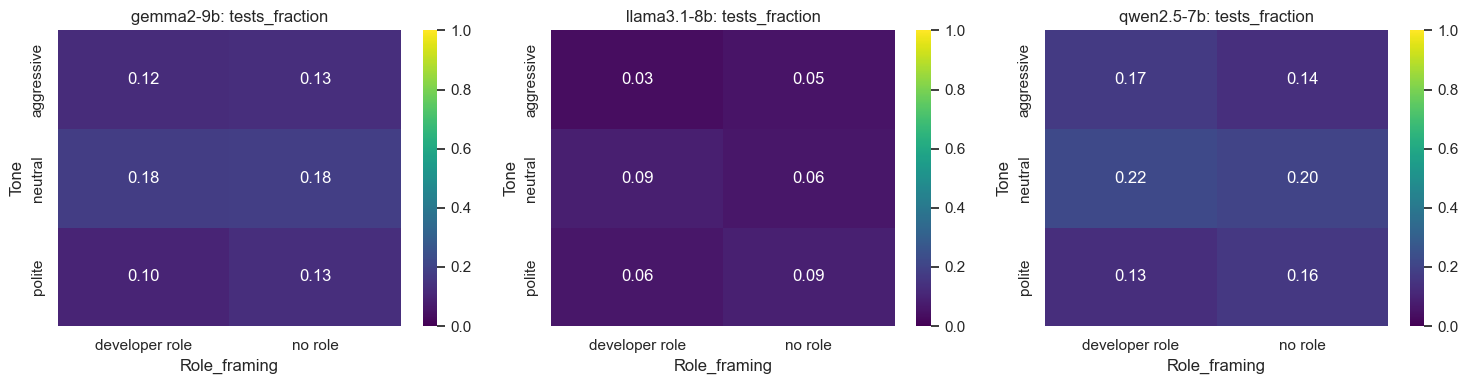

In [11]:
def interaction_heatmap(data: pd.DataFrame, row_factor: str, col_factor: str, metric: str = "tests_fraction") -> None:
    models = sorted(data["model_short"].unique())
    fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4), squeeze=False)
    for ax, model in zip(axes[0], models):
        subset = data[data["model_short"] == model]
        pivot = subset.pivot_table(index=row_factor, columns=col_factor, values=metric, aggfunc="mean")
        sns.heatmap(pivot, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=ax)
        ax.set_title(f"{model}: {metric}")
    plt.tight_layout()
    plt.show()

if {"Tone", "Format"}.issubset(technique_factors):
    interaction_heatmap(df, "Tone", "Format", "tests_fraction")
if {"Role_framing", "Format"}.issubset(technique_factors):
    interaction_heatmap(df, "Role_framing", "Format", "tests_fraction")
if {"Tone", "Role_framing"}.issubset(technique_factors):
    interaction_heatmap(df, "Tone", "Role_framing", "tests_fraction")

## Fixed-Effect Models

These linear fixed-effect models estimate prompt-technique associations while controlling for `model_short` and `problem_id`. Treat them as descriptive, not causal proof. Coefficients are easiest to read as average changes relative to the reference categories.

In [12]:
def fit_fixed_effect(metric: str, interactions: bool = False):
    if not STATSMODELS_AVAILABLE:
        print("statsmodels is not available in this environment.")
        return None
    factors = [f"C({factor})" for factor in technique_factors]
    if interactions and len(technique_factors) >= 2:
        # Main effects plus pairwise interactions among prompt techniques.
        prompt_terms = " + ".join(factors)
        interaction_terms = " + ".join(
            f"C({a}):C({b})" for i, a in enumerate(technique_factors) for b in technique_factors[i + 1:]
        )
        rhs = f"{prompt_terms} + {interaction_terms} + C(model_short) + C(problem_id)"
    else:
        rhs = " + ".join([*factors, "C(model_short)", "C(problem_id)"])
    formula = f"{metric} ~ {rhs}"
    model_data = df[[metric, "model_short", "problem_id", *technique_factors]].dropna()
    result = smf.ols(formula, data=model_data).fit(cov_type="HC3")
    print(formula)
    return result

regression_metrics = ["passed_int", "tests_fraction", "duration_seconds", "completion_tokens", "likely_code_only", "extra_text_ratio"]
regression_rows = []
for metric in regression_metrics:
    result = fit_fixed_effect(metric)
    if result is None:
        continue
    params = result.params.rename("coef").to_frame()
    params["std_err"] = result.bse
    params["p_value"] = result.pvalues
    params["metric"] = metric
    params["term"] = params.index
    regression_rows.append(params.reset_index(drop=True))

regression_table = pd.concat(regression_rows, ignore_index=True) if regression_rows else pd.DataFrame()
technique_terms = regression_table[regression_table["term"].str.contains("Tone|Role_framing|Format|Pressure", regex=True, na=False)].copy()
technique_terms.to_csv(OUTPUT_DIR / "fixed_effect_prompt_technique_models.csv", index=False)

display(technique_terms.style.format({"coef": "{:+.4f}", "std_err": "{:.4f}", "p_value": "{:.4f}"}))
print(f"Saved: {OUTPUT_DIR / 'fixed_effect_prompt_technique_models.csv'}")

passed_int ~ C(Tone) + C(Role_framing) + C(Format) + C(model_short) + C(problem_id)
tests_fraction ~ C(Tone) + C(Role_framing) + C(Format) + C(model_short) + C(problem_id)
duration_seconds ~ C(Tone) + C(Role_framing) + C(Format) + C(model_short) + C(problem_id)
completion_tokens ~ C(Tone) + C(Role_framing) + C(Format) + C(model_short) + C(problem_id)
likely_code_only ~ C(Tone) + C(Role_framing) + C(Format) + C(model_short) + C(problem_id)
extra_text_ratio ~ C(Tone) + C(Role_framing) + C(Format) + C(model_short) + C(problem_id)


,coef,std_err,p_value,metric,term
1,+0.0300,0.0120,0.0123,passed_int,C(Tone)[T.neutral]
2,+0.0011,0.0118,0.9247,passed_int,C(Tone)[T.polite]
3,+0.0081,0.0098,0.4047,passed_int,C(Role_framing)[T.no role]
4,+0.0122,0.0118,0.3015,passed_int,C(Format)[T.plaintext]
5,+0.0089,0.0120,0.4581,passed_int,C(Format)[T.xml]
58,+0.0462,0.0129,0.0003,tests_fraction,C(Tone)[T.neutral]
59,+0.0038,0.0126,0.7626,tests_fraction,C(Tone)[T.polite]
60,+0.0053,0.0105,0.6152,tests_fraction,C(Role_framing)[T.no role]
61,+0.0162,0.0128,0.2051,tests_fraction,C(Format)[T.plaintext]
62,+0.0076,0.0128,0.5521,tests_fraction,C(Format)[T.xml]


Saved: /Users/macos/LearningSpace/ue-courses/Thesis/01PilotPhrase/pivot_problem_dataset/analysis_outputs/fixed_effect_prompt_technique_models.csv


## Error Modes

This section checks whether prompt techniques change the kind of failures models produce, not just whether they pass.

,model_short,error_category,runs,share_within_model
4,gemma2-9b,wrong_answer,443,49.2%
0,gemma2-9b,name_not_defined,355,39.4%
1,gemma2-9b,none,85,9.4%
2,gemma2-9b,syntax_error,9,1.0%
3,gemma2-9b,timeout,8,0.9%
6,llama3.1-8b,name_not_defined,506,56.2%
10,llama3.1-8b,wrong_answer,251,27.9%
5,llama3.1-8b,missing_or_empty_code,97,10.8%
7,llama3.1-8b,none,35,3.9%
9,llama3.1-8b,timeout,9,1.0%



=== Error category by Tone ===


error_category,import_error,missing_or_empty_code,name_not_defined,none,syntax_error,timeout,wrong_answer
Tone,,,,,,,
aggressive,0.1%,3.9%,47.9%,7.9%,0.6%,0.8%,38.9%
neutral,0.0%,7.1%,33.9%,10.9%,0.4%,0.9%,46.8%
polite,0.0%,0.1%,53.1%,8.0%,0.3%,0.8%,37.7%



=== Error category by Role_framing ===


error_category,import_error,missing_or_empty_code,name_not_defined,none,syntax_error,timeout,wrong_answer
Role_framing,,,,,,,
developer role,0.0%,5.4%,43.6%,8.5%,0.4%,0.7%,41.4%
no role,0.1%,2.0%,46.4%,9.3%,0.4%,1.0%,40.8%



=== Error category by Format ===


error_category,import_error,missing_or_empty_code,name_not_defined,none,syntax_error,timeout,wrong_answer
Format,,,,,,,
json,0.0%,2.0%,44.6%,8.2%,0.4%,1.0%,43.8%
plaintext,0.0%,2.6%,46.2%,9.4%,0.3%,0.7%,40.8%
xml,0.1%,6.6%,44.1%,9.1%,0.6%,0.8%,38.8%


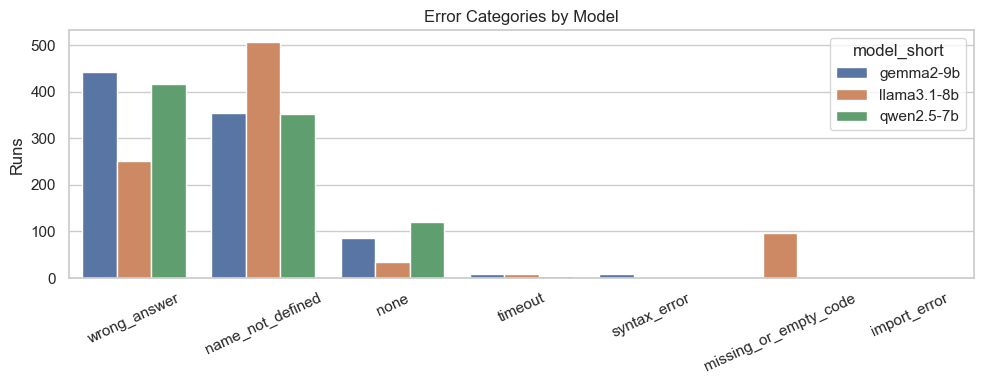

In [13]:
error_overview = (
    df.groupby(["model_short", "error_category"])
    .size()
    .rename("runs")
    .reset_index()
)
error_overview["share_within_model"] = error_overview["runs"] / error_overview.groupby("model_short")["runs"].transform("sum")
display(error_overview.sort_values(["model_short", "runs"], ascending=[True, False]).style.format({"share_within_model": "{:.1%}"}))

for factor in technique_factors:
    print(f"\n=== Error category by {factor} ===")
    table = pd.crosstab(df[factor], df["error_category"], normalize="index")
    display(table.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(10, 4))
sns.countplot(data=df, x="error_category", hue="model_short", ax=ax)
ax.set_title("Error Categories by Model")
ax.set_xlabel("")
ax.set_ylabel("Runs")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## Best and Worst Prompt Templates

This ranks complete prompt templates, which helps identify whether the winning behavior comes from a single factor or a combination.

In [14]:
template_summary = (
    df.groupby(["template_id", *technique_factors])
    .agg(
        runs=("task_id", "size"),
        models=("model_short", "nunique"),
        problems=("problem_id", "nunique"),
        pass_rate=("passed_int", "mean"),
        tests_fraction=("tests_fraction", "mean"),
        avg_duration_seconds=("duration_seconds", "mean"),
        avg_completion_tokens=("completion_tokens", "mean"),
        code_only_rate=("likely_code_only", "mean"),
        code_extraction_rate=("has_extracted_code", "mean"),
    )
    .reset_index()
    .sort_values(["tests_fraction", "pass_rate"], ascending=False)
)
template_summary.to_csv(OUTPUT_DIR / "prompt_template_summary.csv", index=False)

display(template_summary.head(10).style.format({
    "pass_rate": "{:.1%}",
    "tests_fraction": "{:.1%}",
    "avg_duration_seconds": "{:.2f}",
    "avg_completion_tokens": "{:.1f}",
    "code_only_rate": "{:.1%}",
    "code_extraction_rate": "{:.1%}",
}))
print("Worst templates:")
display(template_summary.tail(10).style.format({
    "pass_rate": "{:.1%}",
    "tests_fraction": "{:.1%}",
    "avg_duration_seconds": "{:.2f}",
    "avg_completion_tokens": "{:.1f}",
    "code_only_rate": "{:.1%}",
    "code_extraction_rate": "{:.1%}",
}))
print(f"Saved: {OUTPUT_DIR / 'prompt_template_summary.csv'}")

,template_id,Tone,Role_framing,Format,runs,models,problems,pass_rate,tests_fraction,avg_duration_seconds,avg_completion_tokens,code_only_rate,code_extraction_rate
0,1,neutral,no role,plaintext,150,3,50,13.3%,18.4%,12.28,400.2,58.0%,100.0%
4,5,neutral,developer role,json,150,3,50,12.7%,17.7%,13.13,431.3,55.3%,98.0%
5,6,neutral,developer role,xml,150,3,50,12.7%,16.1%,12.97,421.0,61.3%,80.0%
2,3,neutral,no role,xml,150,3,50,11.3%,15.2%,12.09,393.3,79.3%,96.0%
3,4,neutral,developer role,plaintext,150,3,50,9.3%,14.5%,12.19,400.0,63.3%,85.3%
6,7,polite,no role,plaintext,150,3,50,9.3%,14.5%,20.52,681.9,2.0%,100.0%
8,9,polite,no role,xml,150,3,50,10.0%,13.0%,21.51,716.9,0.7%,100.0%
16,17,aggressive,developer role,json,150,3,50,8.7%,12.6%,19.68,664.1,0.0%,98.0%
12,13,aggressive,no role,plaintext,150,3,50,10.0%,12.5%,21.31,719.5,0.0%,99.3%
7,8,polite,no role,json,150,3,50,9.3%,10.9%,21.82,728.3,1.3%,100.0%


Worst templates:


,template_id,Tone,Role_framing,Format,runs,models,problems,pass_rate,tests_fraction,avg_duration_seconds,avg_completion_tokens,code_only_rate,code_extraction_rate
12,13,aggressive,no role,plaintext,150,3,50,10.0%,12.5%,21.31,719.5,0.0%,99.3%
7,8,polite,no role,json,150,3,50,9.3%,10.9%,21.82,728.3,1.3%,100.0%
14,15,aggressive,no role,xml,150,3,50,8.0%,10.8%,20.36,682.2,2.0%,94.0%
1,2,neutral,no role,json,150,3,50,6.0%,10.7%,13.08,429.8,56.7%,98.0%
17,18,aggressive,developer role,xml,150,3,50,6.7%,10.3%,19.75,660.5,2.0%,90.7%
9,10,polite,developer role,plaintext,150,3,50,7.3%,10.1%,21.37,713.4,2.7%,100.0%
15,16,aggressive,developer role,plaintext,150,3,50,7.3%,9.9%,20.78,701.4,0.0%,100.0%
10,11,polite,developer role,json,150,3,50,6.0%,9.4%,21.68,725.1,1.3%,99.3%
11,12,polite,developer role,xml,150,3,50,6.0%,9.3%,21.91,732.0,0.7%,100.0%
13,14,aggressive,no role,json,150,3,50,6.7%,8.9%,20.51,692.8,0.0%,94.7%


Saved: /Users/macos/LearningSpace/ue-courses/Thesis/01PilotPhrase/pivot_problem_dataset/analysis_outputs/prompt_template_summary.csv


## Inspect Concrete Examples

Use this cell to examine representative successes/failures for a model, template, or technique level.

In [15]:
def show_examples(
    data: pd.DataFrame,
    *,
    model: str | None = None,
    factor: str | None = None,
    level: str | None = None,
    passed: bool | None = None,
    n: int = 3,
    random_state: int = RANDOM_SEED,
) -> pd.DataFrame:
    subset = data.copy()
    if model is not None:
        subset = subset[subset["model_short"] == model]
    if factor is not None and level is not None:
        subset = subset[subset[factor] == level]
    if passed is not None:
        subset = subset[subset["passed_int"] == int(passed)]
    cols = [
        "model_short", "problem_id", "template_id", *technique_factors,
        "passed_int", "tests_passed", "tests_total", "error_category",
        "response_text", "extracted_code",
    ]
    if len(subset) == 0:
        return subset[cols]
    return subset.sample(min(n, len(subset)), random_state=random_state)[cols]

# Example usage:
# display(show_examples(df, model="gemma2-9b", factor="Format", level="json", passed=False, n=2))
display(show_examples(df, n=2))

,model_short,problem_id,template_id,Tone,Role_framing,Format,passed_int,tests_passed,tests_total,error_category,response_text,extracted_code
1339,llama3.1-8b,25,8,polite,no role,json,0,0,7,name_not_defined,"Here's a high-quality Python solution for the problem:\n\n```python\nfrom typing import Tuple\nimport math\n\ndef distance(point1: Tuple[float, float], poin...","from typing import Tuple\nimport math\n\ndef distance(point1: Tuple[float, float], point2: Tuple[float, float]) -> float:\n """"""\n Calculate the Euclid..."
1222,llama3.1-8b,18,17,aggressive,developer role,json,0,0,7,name_not_defined,"**Max Charity Revenue**\n=======================\n\nGiven the production constraints and menu prices, we need to find the maximum total revenue that can be ...","print(max_charity_revenue(180, 110, 40, (2, 1), 65, (3, 2))) # Output: 3800\nprint(max_charity_revenue(100, 50, 40, (2, 1), 65, (3, 2))) # Output: 2000"


## Auto-Written Interpretation Aids

These tables surface likely takeaways. Read them together with the confidence intervals and model-specific plots above.

In [16]:
def top_effects(summary: pd.DataFrame, metric: str, k: int = 8) -> pd.DataFrame:
    subset = summary[summary["metric"] == metric].copy()
    if subset.empty:
        return subset
    subset["abs_delta"] = subset["mean_delta"].abs()
    return subset.sort_values("abs_delta", ascending=False).head(k).drop(columns="abs_delta")

print("Largest paired effects on tests_fraction:")
display(top_effects(paired_summary, "tests_fraction").style.format({"mean_delta": "{:+.3f}", "ci_low": "{:+.3f}", "ci_high": "{:+.3f}"}))

print("Largest paired effects on pass/fail:")
display(top_effects(paired_summary, "passed_int").style.format({"mean_delta": "{:+.3f}", "ci_low": "{:+.3f}", "ci_high": "{:+.3f}"}))

print("Largest paired behavior effects on completion_tokens:")
display(top_effects(paired_summary, "completion_tokens").style.format({"mean_delta": "{:+.1f}", "ci_low": "{:+.1f}", "ci_high": "{:+.1f}"}))

print("Largest paired behavior effects on likely_code_only:")
display(top_effects(paired_summary, "likely_code_only").style.format({"mean_delta": "{:+.3f}", "ci_low": "{:+.3f}", "ci_high": "{:+.3f}"}))

Largest paired effects on tests_fraction:


,factor,metric,reference,level,mean_delta,ci_low,ci_high,n_pairs
3,Tone,tests_fraction,neutral,aggressive,-0.046,-0.075,-0.018,150
2,Tone,tests_fraction,neutral,polite,-0.042,-0.077,-0.008,150
20,Format,tests_fraction,plaintext,json,-0.016,-0.038,+0.006,150
21,Format,tests_fraction,plaintext,xml,-0.009,-0.033,+0.016,150
13,Role_framing,tests_fraction,no role,developer role,-0.005,-0.022,+0.011,150


Largest paired effects on pass/fail:


,factor,metric,reference,level,mean_delta,ci_low,ci_high,n_pairs
1,Tone,passed_int,neutral,aggressive,-0.030,-0.059,-0.001,150
0,Tone,passed_int,neutral,polite,-0.029,-0.061,+0.003,150
18,Format,passed_int,plaintext,json,-0.012,-0.034,+0.010,150
12,Role_framing,passed_int,no role,developer role,-0.008,-0.025,+0.008,150
19,Format,passed_int,plaintext,xml,-0.003,-0.025,+0.018,150


Largest paired behavior effects on completion_tokens:


,factor,metric,reference,level,mean_delta,ci_low,ci_high,n_pairs
6,Tone,completion_tokens,neutral,polite,+303.7,+280.2,+327.1,150
7,Tone,completion_tokens,neutral,aggressive,+274.1,+245.6,+302.7,150
24,Format,completion_tokens,plaintext,json,+9.2,-3.9,+22.2,150
25,Format,completion_tokens,plaintext,xml,-1.7,-15.9,+12.4,150
15,Role_framing,completion_tokens,no role,developer role,+0.4,-9.0,+9.9,150


Largest paired behavior effects on likely_code_only:


,factor,metric,reference,level,mean_delta,ci_low,ci_high,n_pairs
9,Tone,likely_code_only,neutral,aggressive,-0.617,-0.671,-0.562,150
8,Tone,likely_code_only,neutral,polite,-0.609,-0.666,-0.552,150
27,Format,likely_code_only,plaintext,xml,+0.033,+0.010,+0.057,150
26,Format,likely_code_only,plaintext,json,-0.019,-0.042,+0.004,150
16,Role_framing,likely_code_only,no role,developer role,-0.015,-0.031,+0.002,150


# Performance by tones

/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/1053412606.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tone_perf, x="Tone", y="mean", palette="viridis")


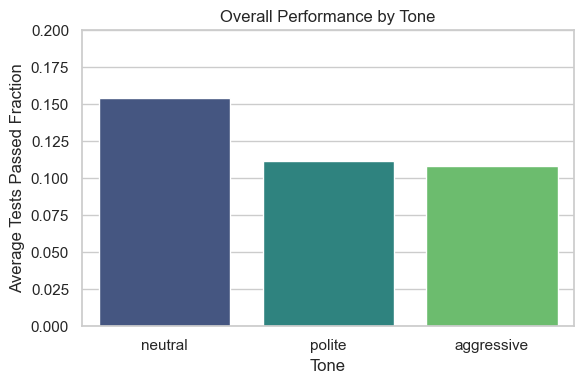

In [18]:
# Visualize overall performance (tests_fraction) by Tone, aggregated across all models and templates.
tone_perf = (
    df.groupby("Tone")["tests_fraction"]
    .agg(["mean", "count", "std"])
    .reset_index()
    .sort_values("mean", ascending=False)
)
plt.figure(figsize=(6, 4))
sns.barplot(data=tone_perf, x="Tone", y="mean", palette="viridis")
plt.ylabel("Average Tests Passed Fraction")
plt.xlabel("Tone")
plt.title("Overall Performance by Tone")
plt.ylim(0, 0.2)
plt.tight_layout()
plt.show()

,model_short,Tone,mean,count,std
1,gemma2-9b,neutral,0.179524,300,0.333267
0,gemma2-9b,aggressive,0.127619,300,0.309628
2,gemma2-9b,polite,0.114286,300,0.298793
5,llama3.1-8b,polite,0.074762,300,0.239564
4,llama3.1-8b,neutral,0.072381,300,0.233234
3,llama3.1-8b,aggressive,0.043810,300,0.182091
7,qwen2.5-7b,neutral,0.210952,300,0.397319
6,qwen2.5-7b,aggressive,0.152857,300,0.343781
8,qwen2.5-7b,polite,0.146667,300,0.340414


/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/2313202057.py:12: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  g = sns.catplot(
/Users/macos/.pyenv/versions/3.11.10/lib/python3.11/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/2313202057.py:28: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


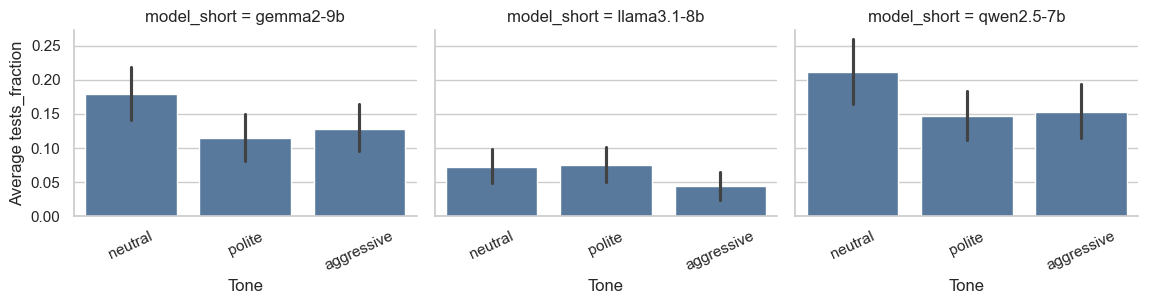

In [22]:
# Performance by Tone for each model, visualized with bar plots and confidence intervals
if "Tone" not in df.columns:
    print("No 'Tone' column in dataframe.")
else:
    tone_model = (
        df.groupby(["model_short", "Tone"], dropna=False)["tests_fraction"]
        .agg(mean="mean", count="size", std="std")
        .reset_index()
    )
    display(tone_model.sort_values(["model_short", "mean"], ascending=[True, False]))

    g = sns.catplot(
        data=df,
        x="Tone",
        y="tests_fraction",
        col="model_short",
        kind="bar",
        ci=95,
        col_wrap=3,
        height=3.2,
        aspect=1.2,
        order=ordered_levels(df, "Tone"),
        color="#4C78A8",
    )
    g.set_axis_labels("Tone", "Average tests_fraction")
    for ax in g.axes.flatten():
        ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()

# Performance by roles

/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/3129092524.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=role_summary, x="Role_framing", y="mean", palette="viridis")


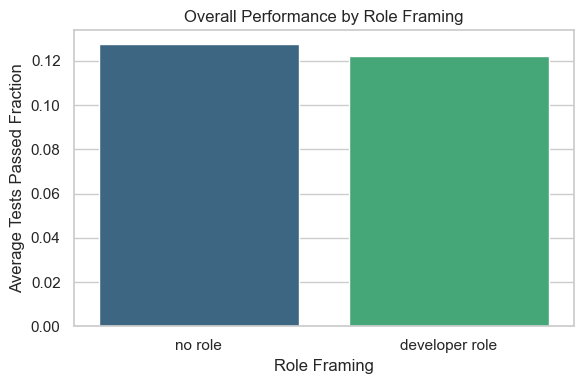

,model_short,Role_framing,mean,count,std
1,gemma2-9b,no role,0.148254,450,0.325454
0,gemma2-9b,developer role,0.132698,450,0.304633
3,llama3.1-8b,no role,0.067619,450,0.228844
2,llama3.1-8b,developer role,0.059683,450,0.210995
4,qwen2.5-7b,developer role,0.173968,450,0.364101
5,qwen2.5-7b,no role,0.166349,450,0.360662


/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/3129092524.py:24: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  g = sns.catplot(
/Users/macos/.pyenv/versions/3.11.10/lib/python3.11/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/3129092524.py:40: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


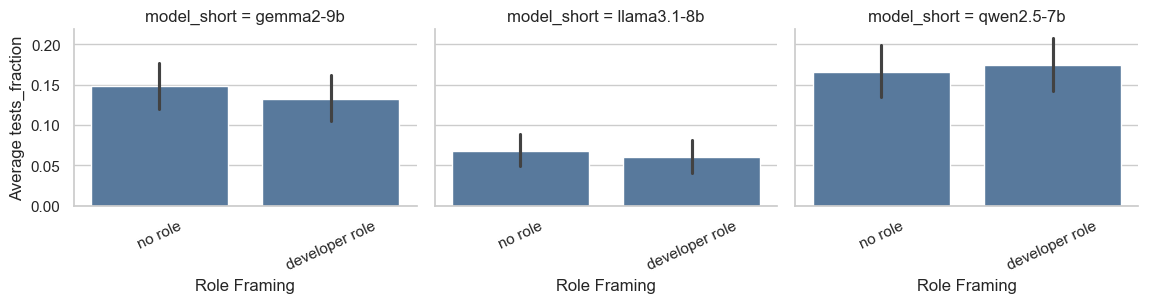

In [23]:
# Overall performance by Role_framing
role_summary = (
    df.groupby("Role_framing")["tests_fraction"]
    .agg(["mean", "count", "std"])
    .reset_index()
    .sort_values("mean", ascending=False)
)
plt.figure(figsize=(6, 4))
sns.barplot(data=role_summary, x="Role_framing", y="mean", palette="viridis")
plt.ylabel("Average Tests Passed Fraction")
plt.xlabel("Role Framing")
plt.title("Overall Performance by Role Framing")
plt.tight_layout()
plt.show()

# Performance by Role_framing for each model
role_model = (
    df.groupby(["model_short", "Role_framing"], dropna=False)["tests_fraction"]
    .agg(mean="mean", count="size", std="std")
    .reset_index()
)
display(role_model.sort_values(["model_short", "mean"], ascending=[True, False]))

g = sns.catplot(
    data=df,
    x="Role_framing",
    y="tests_fraction",
    col="model_short",
    kind="bar",
    ci=95,
    col_wrap=3,
    height=3.2,
    aspect=1.2,
    order=ordered_levels(df, "Role_framing"),
    color="#4C78A8",
)
g.set_axis_labels("Role Framing", "Average tests_fraction")
for ax in g.axes.flatten():
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

# Performance by format

/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/1582536290.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=format_summary, x="Format", y="mean", palette="viridis")


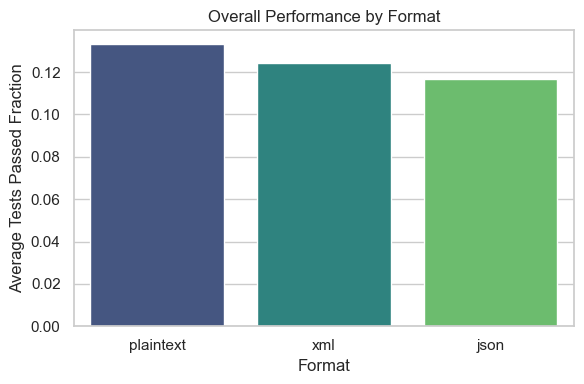

,model_short,Format,mean,count,std
2,gemma2-9b,xml,0.157619,300,0.330858
0,gemma2-9b,json,0.132857,300,0.308186
1,gemma2-9b,plaintext,0.130952,300,0.306118
3,llama3.1-8b,json,0.066667,300,0.219310
4,llama3.1-8b,plaintext,0.065714,300,0.225123
5,llama3.1-8b,xml,0.058571,300,0.216160
7,qwen2.5-7b,plaintext,0.202381,300,0.387938
8,qwen2.5-7b,xml,0.157143,300,0.354289
6,qwen2.5-7b,json,0.150952,300,0.341840


/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/1582536290.py:24: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  g = sns.catplot(
/Users/macos/.pyenv/versions/3.11.10/lib/python3.11/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/1582536290.py:40: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


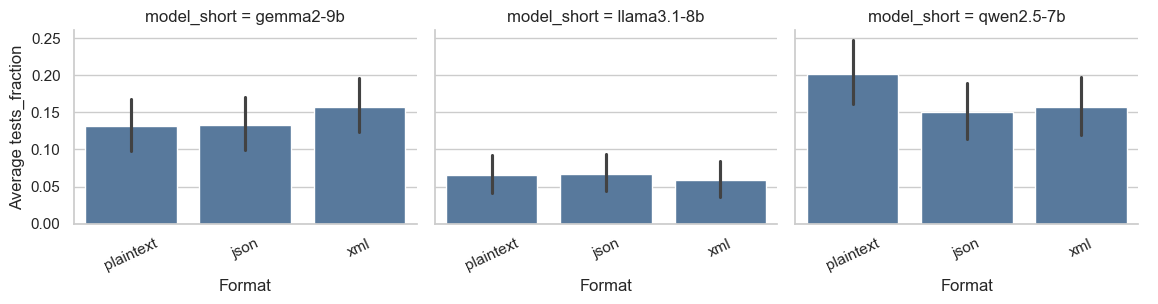

In [24]:
# Overall performance by Format
format_summary = (
    df.groupby("Format")["tests_fraction"]
    .agg(["mean", "count", "std"])
    .reset_index()
    .sort_values("mean", ascending=False)
)
plt.figure(figsize=(6, 4))
sns.barplot(data=format_summary, x="Format", y="mean", palette="viridis")
plt.ylabel("Average Tests Passed Fraction")
plt.xlabel("Format")
plt.title("Overall Performance by Format")
plt.tight_layout()
plt.show()

# Performance by Format for each model
format_model = (
    df.groupby(["model_short", "Format"], dropna=False)["tests_fraction"]
    .agg(mean="mean", count="size", std="std")
    .reset_index()
)
display(format_model.sort_values(["model_short", "mean"], ascending=[True, False]))

g = sns.catplot(
    data=df,
    x="Format",
    y="tests_fraction",
    col="model_short",
    kind="bar",
    ci=95,
    col_wrap=3,
    height=3.2,
    aspect=1.2,
    order=ordered_levels(df, "Format"),
    color="#4C78A8",
)
g.set_axis_labels("Format", "Average tests_fraction")
for ax in g.axes.flatten():
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

# Duration

# Duration by tone

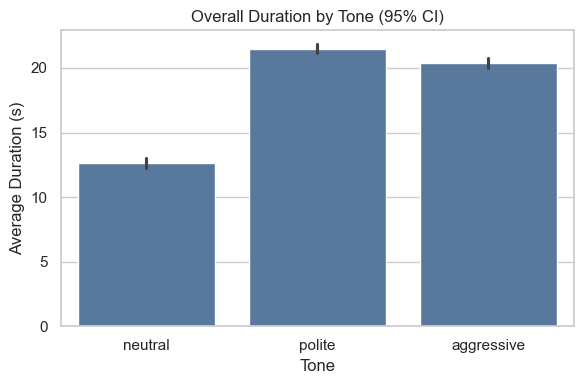

/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/2852390547.py:15: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  g = sns.catplot(
/Users/macos/.pyenv/versions/3.11.10/lib/python3.11/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/2852390547.py:31: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


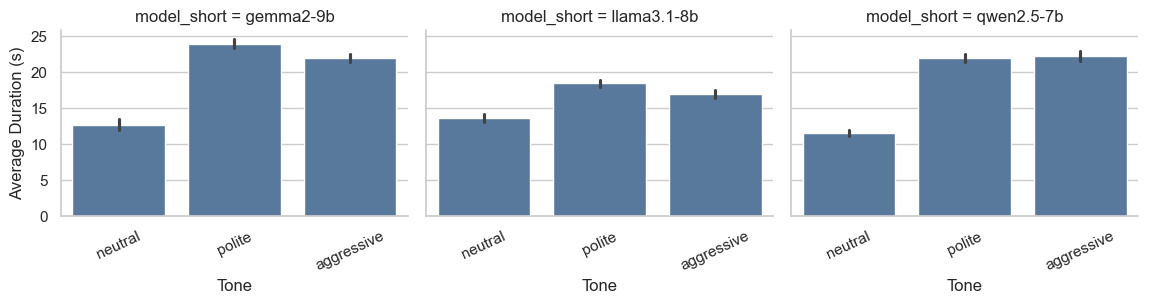

In [25]:
# Duration by Tone: overall and per-model
if "Tone" not in df.columns:
    print("No 'Tone' column in dataframe.")
else:
    # Overall mean duration by Tone with 95% CIs
    plt.figure(figsize=(6, 4))
    sns.barplot(data=df, x="Tone", y="duration_seconds", errorbar=("ci", 95), order=ordered_levels(df, "Tone"), color="#4C78A8")
    plt.xlabel("Tone")
    plt.ylabel("Average Duration (s)")
    plt.title("Overall Duration by Tone (95% CI)")
    plt.tight_layout()
    plt.show()

    # Duration by Tone for each model
    g = sns.catplot(
        data=df,
        x="Tone",
        y="duration_seconds",
        col="model_short",
        kind="bar",
        ci=95,
        col_wrap=3,
        height=3.2,
        aspect=1.2,
        order=ordered_levels(df, "Tone"),
        color="#4C78A8",
    )
    g.set_axis_labels("Tone", "Average Duration (s)")
    for ax in g.axes.flatten():
        ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()

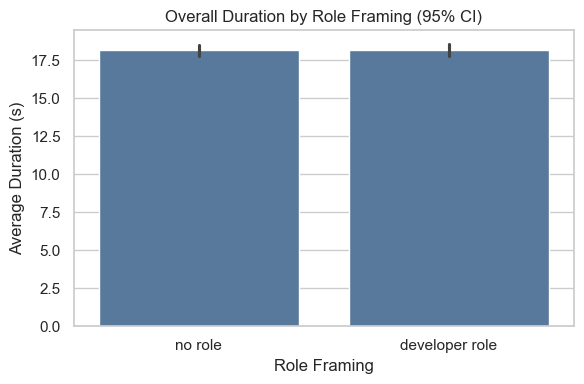

/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/673635201.py:22: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  g = sns.catplot(
/Users/macos/.pyenv/versions/3.11.10/lib/python3.11/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/673635201.py:38: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


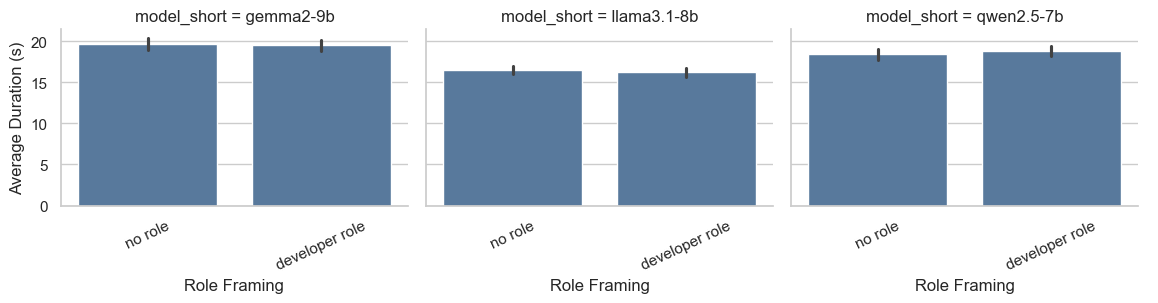

In [26]:
# Duration by Role_framing: overall and per-model
if "Role_framing" not in df.columns:
    print("No 'Role_framing' column in dataframe.")
else:
    # Overall mean duration by Role_framing with 95% CIs
    plt.figure(figsize=(6, 4))
    sns.barplot(
        data=df,
        x="Role_framing",
        y="duration_seconds",
        errorbar=("ci", 95),
        order=ordered_levels(df, "Role_framing"),
        color="#4C78A8"
    )
    plt.xlabel("Role Framing")
    plt.ylabel("Average Duration (s)")
    plt.title("Overall Duration by Role Framing (95% CI)")
    plt.tight_layout()
    plt.show()

    # Duration by Role_framing for each model
    g = sns.catplot(
        data=df,
        x="Role_framing",
        y="duration_seconds",
        col="model_short",
        kind="bar",
        ci=95,
        col_wrap=3,
        height=3.2,
        aspect=1.2,
        order=ordered_levels(df, "Role_framing"),
        color="#4C78A8",
    )
    g.set_axis_labels("Role Framing", "Average Duration (s)")
    for ax in g.axes.flatten():
        ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()

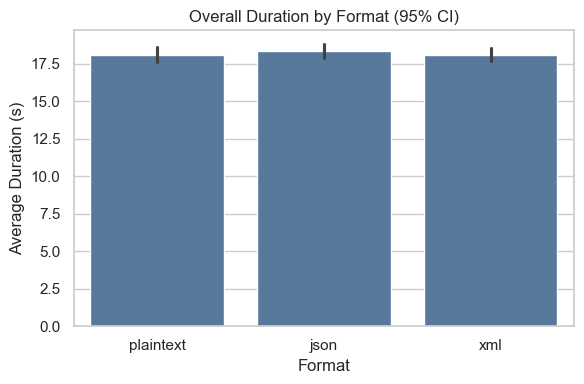

/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/2573458554.py:22: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  g = sns.catplot(
/Users/macos/.pyenv/versions/3.11.10/lib/python3.11/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/2573458554.py:38: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


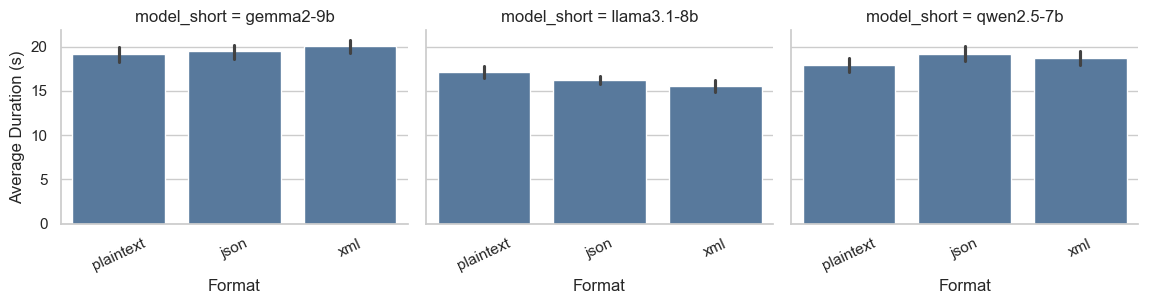

In [27]:
# Duration by Format: overall and per-model
if "Format" not in df.columns:
    print("No 'Format' column in dataframe.")
else:
    # Overall mean duration by Format with 95% CIs
    plt.figure(figsize=(6, 4))
    sns.barplot(
        data=df,
        x="Format",
        y="duration_seconds",
        errorbar=("ci", 95),
        order=ordered_levels(df, "Format"),
        color="#4C78A8"
    )
    plt.xlabel("Format")
    plt.ylabel("Average Duration (s)")
    plt.title("Overall Duration by Format (95% CI)")
    plt.tight_layout()
    plt.show()

    # Duration by Format for each model
    g = sns.catplot(
        data=df,
        x="Format",
        y="duration_seconds",
        col="model_short",
        kind="bar",
        ci=95,
        col_wrap=3,
        height=3.2,
        aspect=1.2,
        order=ordered_levels(df, "Format"),
        color="#4C78A8",
    )
    g.set_axis_labels("Format", "Average Duration (s)")
    for ax in g.axes.flatten():
        ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()

# completion_tokens

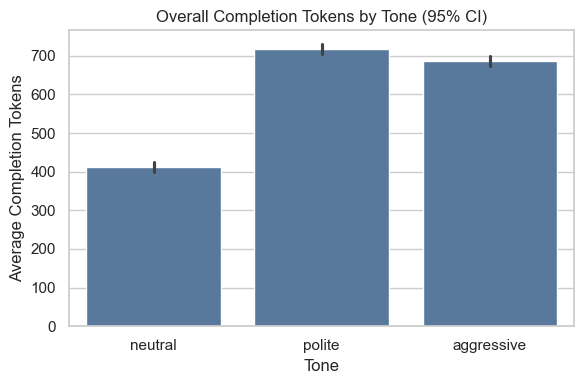

/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/3312306652.py:20: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  g = sns.catplot(
/Users/macos/.pyenv/versions/3.11.10/lib/python3.11/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/3312306652.py:36: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


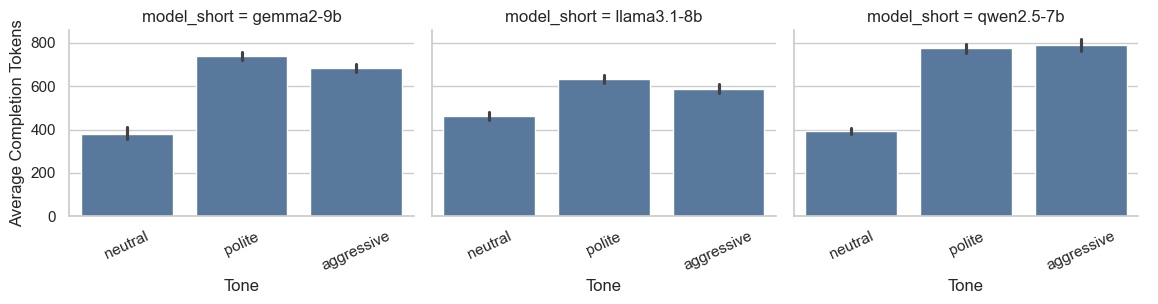

In [28]:
# Visualize completion_tokens: overall by Tone, and per-model by Tone

# Overall mean completion_tokens by Tone with 95% CIs
plt.figure(figsize=(6, 4))
sns.barplot(
    data=df,
    x="Tone",
    y="completion_tokens",
    errorbar=("ci", 95),
    order=ordered_levels(df, "Tone"),
    color="#4C78A8"
)
plt.xlabel("Tone")
plt.ylabel("Average Completion Tokens")
plt.title("Overall Completion Tokens by Tone (95% CI)")
plt.tight_layout()
plt.show()

# completion_tokens by Tone for each model
g = sns.catplot(
    data=df,
    x="Tone",
    y="completion_tokens",
    col="model_short",
    kind="bar",
    ci=95,
    col_wrap=3,
    height=3.2,
    aspect=1.2,
    order=ordered_levels(df, "Tone"),
    color="#4C78A8",
)
g.set_axis_labels("Tone", "Average Completion Tokens")
for ax in g.axes.flatten():
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

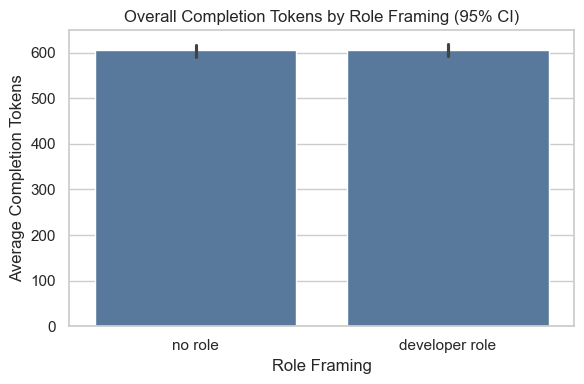

/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/1158270966.py:18: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  g = sns.catplot(
/Users/macos/.pyenv/versions/3.11.10/lib/python3.11/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/1158270966.py:34: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


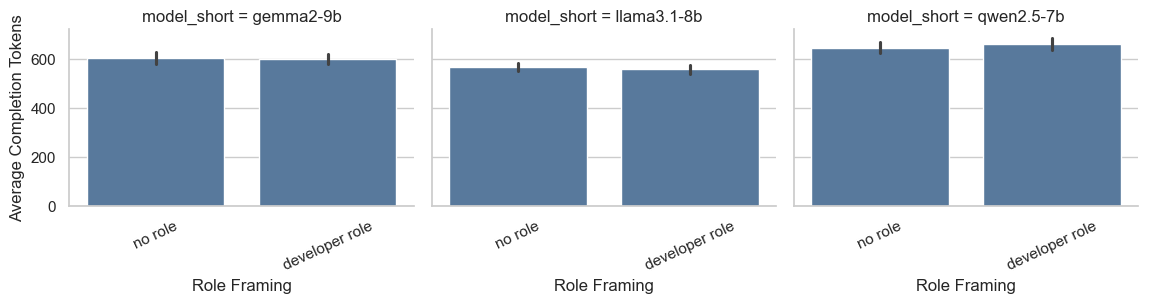

In [ ]:
# Visualize overall completion_tokens by Role_framing, overall and per-model
# Overall mean completion_tokens by Role_framing with 95% CIs
plt.figure(figsize=(6, 4))
sns.barplot(
    data=df,
    x="Role_framing",
    y="completion_tokens",
    errorbar=("ci", 95),
    order=ordered_levels(df, "Role_framing"),
    color="#4C78A8"
)
plt.xlabel("Role Framing")
plt.ylabel("Average Completion Tokens")
plt.title("Overall Completion Tokens by Role Framing (95% CI)")
plt.tight_layout()
plt.show()
# completion_tokens by Role_framing for each model
g = sns.catplot(
    data=df,
    x="Role_framing",
    y="completion_tokens",
    col="model_short",
    kind="bar",
    ci=95,
    col_wrap=3,
    height=3.2,
    aspect=1.2,
    order=ordered_levels(df, "Role_framing"),
    color="#4C78A8",
)
g.set_axis_labels("Role Framing", "Average Completion Tokens")
for ax in g.axes.flatten():
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

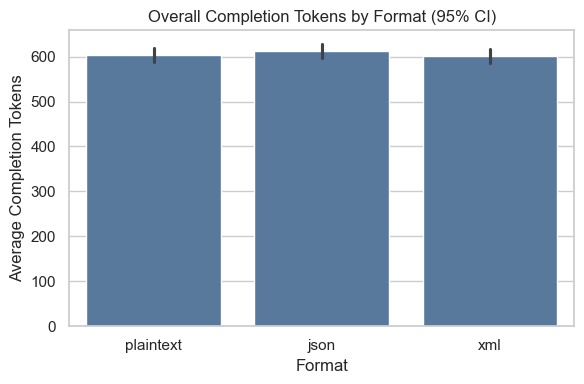

/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/548332514.py:18: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  g = sns.catplot(
/Users/macos/.pyenv/versions/3.11.10/lib/python3.11/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_85581/548332514.py:34: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


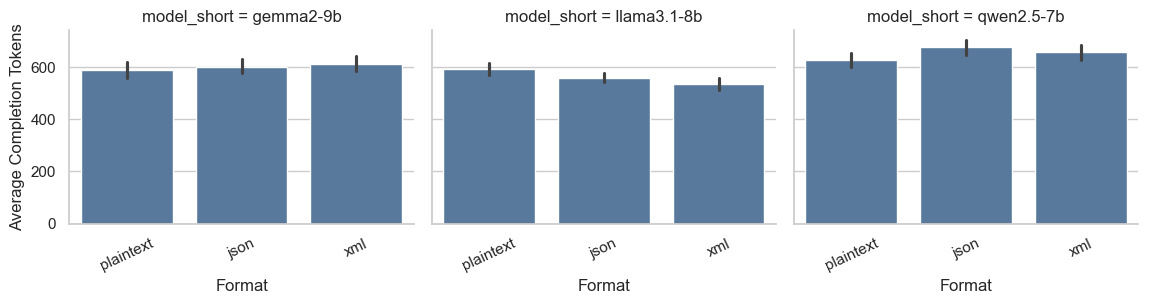

In [33]:
# Visualize overall completion_tokens by format, overall and per-model
# Overall mean completion_tokens by Format with 95% CIs
plt.figure(figsize=(6, 4))
sns.barplot(
    data=df,
    x="Format",
    y="completion_tokens",
    errorbar=("ci", 95),
    order=ordered_levels(df, "Format"),
    color="#4C78A8"
)
plt.xlabel("Format")
plt.ylabel("Average Completion Tokens")
plt.title("Overall Completion Tokens by Format (95% CI)")
plt.tight_layout()
plt.show()
# completion_tokens by Format for each model
g = sns.catplot(
    data=df,
    x="Format",
    y="completion_tokens",
    col="model_short",
    kind="bar",
    ci=95,
    col_wrap=3,
    height=3.2,
    aspect=1.2,
    order=ordered_levels(df, "Format"),
    color="#4C78A8",
)
g.set_axis_labels("Format", "Average Completion Tokens")
for ax in g.axes.flatten():
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()